In [1]:
import importlib

import read_utils
import plot_utils
import train_utils
from models import glm
from models import hgm

importlib.reload(read_utils)
importlib.reload(plot_utils)
importlib.reload(train_utils)
importlib.reload(glm)
importlib.reload(hgm)

<module 'models.hgm' from '/home/julian-zim/Files/Cloud/OneDrive/OneFiles/Linux/Work/Workspaces/UNIVIE/VisualStudioCode/Python/MSc_Thesis/data_exploration/worm-2025-fieseler/models/hgm.py'>

In [2]:
import read_utils
import plot_utils
import train_utils
from models import glm
from models import hgm

import os
import math
from matplotlib import pyplot as plt
import numpy as np
import pandas as pd

from sklearn.metrics import r2_score
from sklearn.model_selection import TimeSeriesSplit, StratifiedKFold

import jax
import jax.numpy as jnp
import optax

In [3]:
def train_joint_model(model, splits, X, B_ll, B_hl):
	seed = jax.random.PRNGKey(0)

	n_neurons = X.shape[1]
	n_behaviors_hl = B_hl.shape[1]
	n_behaviors_ll = B_ll.shape[1]

	# Hyperparamters ============
	n_dimensions = 2

	max_epochs = 500
	min_epochs = 10
	max_patience = 20

	optimizer = optax.adam(1e-3)

	loss_weights = 1, 1
	# ===========================

	# training loop =======================================
	neuron_scores_per_split = list()
	losses_per_split = list()
	losses_tr_per_split = list()
	for train, test in splits:
		# splitting and initializing ===============================================================
		X_train, X_test = X[train], X[test]
		B_hl_train, B_hl_test = B_hl[train], B_hl[test]
		B_ll_train, B_ll_test = B_ll[train], B_ll[test]

		params = model.init_params(seed, (n_neurons, n_dimensions), (n_behaviors_hl, n_dimensions), (n_behaviors_ll, n_neurons), (n_dimensions, n_neurons))
		opt_state = optimizer.init(params)
		# ==========================================================================================

		losses = [model.loss_fn(params, X_test, B_ll_test, B_hl_test, loss_weights).item()]
		losses_tr = [model.loss_fn(params, X_train, B_ll_train, B_hl_train, loss_weights).item()]

		best_params = params
		best_loss = 1.1
		best_loss_tr = 1.1

		patience = 0
		for epoch in range(max_epochs):
			params, opt_state = model.update(optimizer.update, opt_state, params, X, B_ll, B_hl, loss_weights)
			loss = model.loss_fn(params, X_test, B_ll_test, B_hl_test, loss_weights).item()
			loss_tr = model.loss_fn(params, X_train, B_ll_train, B_hl_train, loss_weights).item()

			# early stopping =============
			if epoch > min_epochs:
				if loss < best_loss:
					losses.append(loss)
					losses_tr.append(loss_tr)
					best_loss = loss
					best_loss_tr = loss_tr
					best_params = params
					patience = 0
				else:
					patience += 1
					if patience > max_patience:
						losses_padding = [best_loss for _ in range(max_epochs - len(losses) + 1)]
						losses = losses + losses_padding
						losses_tr_padding = [losses_tr[-1] for _ in range(max_epochs - len(losses_tr) + 1)]
						losses_tr = losses_tr + losses_tr_padding
						break
					losses.append(loss)
					losses_tr.append(loss_tr)
			# ============================
			else:
				losses.append(loss)
				losses_tr.append(loss_tr)
		losses_per_split.append(losses)
		losses_tr_per_split.append(losses_tr)

		# predicting and scoring ========================================================================
		U = best_params['U']
		X_test_man = X_test @ U
		X_test_rec = X_test_man @ jax.numpy.linalg.pinv(U)
		X_test_res = X_test - X_test_rec
		Y_pred = model.predict(B_ll_test, X_test_man, best_params)

		score_per_neuron = [r2_score(trace, trace_pred) for trace, trace_pred in zip(X_test_res.T, Y_pred.T)]
		neuron_scores_per_split.append(score_per_neuron)
		# ===============================================================================================

	# =====================================================

	return np.array(neuron_scores_per_split), np.array(losses_per_split), np.array(losses_tr_per_split)

# GCAMP DATA

In [4]:
path = f'{os.getcwd()}/../data/{os.path.basename(os.getcwd())}/exported_data_/'
filenames, continuous_behaviors, discrete_states, eigenworms, kymographs, traces = read_utils.get_data(path)

### preprocessing

In [5]:
for i in range(len(filenames)):
	mask = eigenworms[i].notna().all(axis=1)
	#continuous_behaviors[i] = continuous_behaviors[i][mask]
	discrete_states[i] = discrete_states[i][mask]
	eigenworms[i] = eigenworms[i][mask]
	traces[i] = traces[i][mask]

	#kymographs[i] = kymographs[i][mask]
	#filenames[i] = filenames[i][mask]

### GLM

In [6]:
selection = ['REV', 'VENTRAL_TURN', 'DORSAL_TURN', 'PAUSE']

# glm_models_params = list()
glm_models_losses = list()
glm_models_losses_tr = list()
glm_models_scores = list()
for i in range(len(filenames)):
	print(f'{i+1}/{len(filenames)}: {filenames[i]}  ', end='')

	cv = StratifiedKFold(n_splits=5)
	splits = list(cv.split(np.zeros(traces[i].values.shape[0]), discrete_states[i]['REV'].values))

	neuron_scores_per_split, losses_per_split, losses_tr_per_split = train_joint_model(glm, splits,
																					   jnp.array(traces[i].values),
																					   jnp.array(eigenworms[i].values),
																					   jnp.array(discrete_states[i][selection].values))

	glm_models_scores.append(neuron_scores_per_split)

	glm_models_losses.append(losses_per_split)
	glm_models_losses_tr.append(losses_tr_per_split)

1/34: ZIM2165_Gcamp7b_worm3-2022_11_28_no_image_data  2/34: ZIM2165_Gcamp7b_worm3-2022-12-10_no_image_data  3/34: ZIM2165_Gcamp7b_worm6-2022-12-10_no_image_data  4/34: ZIM2165_Gcamp7b_worm7-2022-12-10_no_image_data  5/34: 2024-01-17_13-02_wt_FM_worm2_again-2024-01-17_no_image_data  6/34: ZIM2165_Gcamp7b_worm9-2022-12-05_no_image_data  7/34: 2024-01-30_16-32_wt_worm1-2024-01-30_no_image_data  8/34: ZIM2165_Gcamp7b_worm4-2022_11_28_no_image_data  9/34: 2023-11-21_12-39_wt_worm1-2023-11-21_no_image_data  10/34: ZIM2165_Gcamp7b_worm8-2022-12-10_no_image_data  11/34: ZIM2165_Gcamp7b_worm1-2022-12-10_no_image_data  12/34: ZIM2165_Gcamp7b_worm1-2022-11-30_no_image_data  13/34: ZIM2165_Gcamp7b_worm2-2022-12-10_no_image_data  14/34: ZIM2165_Gcamp7b_worm4-2022-12-10_no_image_data  15/34: 2023-11-30_14-31_wt_worm5_FM-2023-11-30_no_image_data  16/34: ZIM2165_Gcamp7b_worm6-2022_11_28_no_image_data  17/34: 2022-11-23_worm9_no_image_data  18/34: 2024-01-11_16-42_wt_FM_worm06-2024-01-11_no_image_data 

### HGM

In [7]:
selection = ['REV', 'VENTRAL_TURN', 'DORSAL_TURN', 'PAUSE']

# hgm_models_params = list()
hgm_models_scores = list()
hgm_models_losses = list()
hgm_models_losses_tr = list()
for i in range(len(filenames)):
	print(f'{i+1}/{len(filenames)}: {filenames[i]}  ', end='')

	cv = StratifiedKFold(n_splits=5)
	splits = list(cv.split(np.zeros(traces[i].shape[0]), discrete_states[i]['REV'].values))

	neuron_scores_per_split, losses_per_plit, losses_tr_per_split = train_joint_model(hgm, splits,
																					  jnp.array(traces[i].values),
																					  jnp.array(eigenworms[i].values),
																					  jnp.array(discrete_states[i][selection].values))

	hgm_models_scores.append(neuron_scores_per_split)

	hgm_models_losses.append(losses_per_plit)
	hgm_models_losses_tr.append(losses_tr_per_split)

1/34: ZIM2165_Gcamp7b_worm3-2022_11_28_no_image_data  2/34: ZIM2165_Gcamp7b_worm3-2022-12-10_no_image_data  3/34: ZIM2165_Gcamp7b_worm6-2022-12-10_no_image_data  4/34: ZIM2165_Gcamp7b_worm7-2022-12-10_no_image_data  5/34: 2024-01-17_13-02_wt_FM_worm2_again-2024-01-17_no_image_data  6/34: ZIM2165_Gcamp7b_worm9-2022-12-05_no_image_data  7/34: 2024-01-30_16-32_wt_worm1-2024-01-30_no_image_data  8/34: ZIM2165_Gcamp7b_worm4-2022_11_28_no_image_data  9/34: 2023-11-21_12-39_wt_worm1-2023-11-21_no_image_data  10/34: ZIM2165_Gcamp7b_worm8-2022-12-10_no_image_data  11/34: ZIM2165_Gcamp7b_worm1-2022-12-10_no_image_data  12/34: ZIM2165_Gcamp7b_worm1-2022-11-30_no_image_data  13/34: ZIM2165_Gcamp7b_worm2-2022-12-10_no_image_data  14/34: ZIM2165_Gcamp7b_worm4-2022-12-10_no_image_data  15/34: 2023-11-30_14-31_wt_worm5_FM-2023-11-30_no_image_data  16/34: ZIM2165_Gcamp7b_worm6-2022_11_28_no_image_data  17/34: 2022-11-23_worm9_no_image_data  18/34: 2024-01-11_16-42_wt_FM_worm06-2024-01-11_no_image_data 

### plots

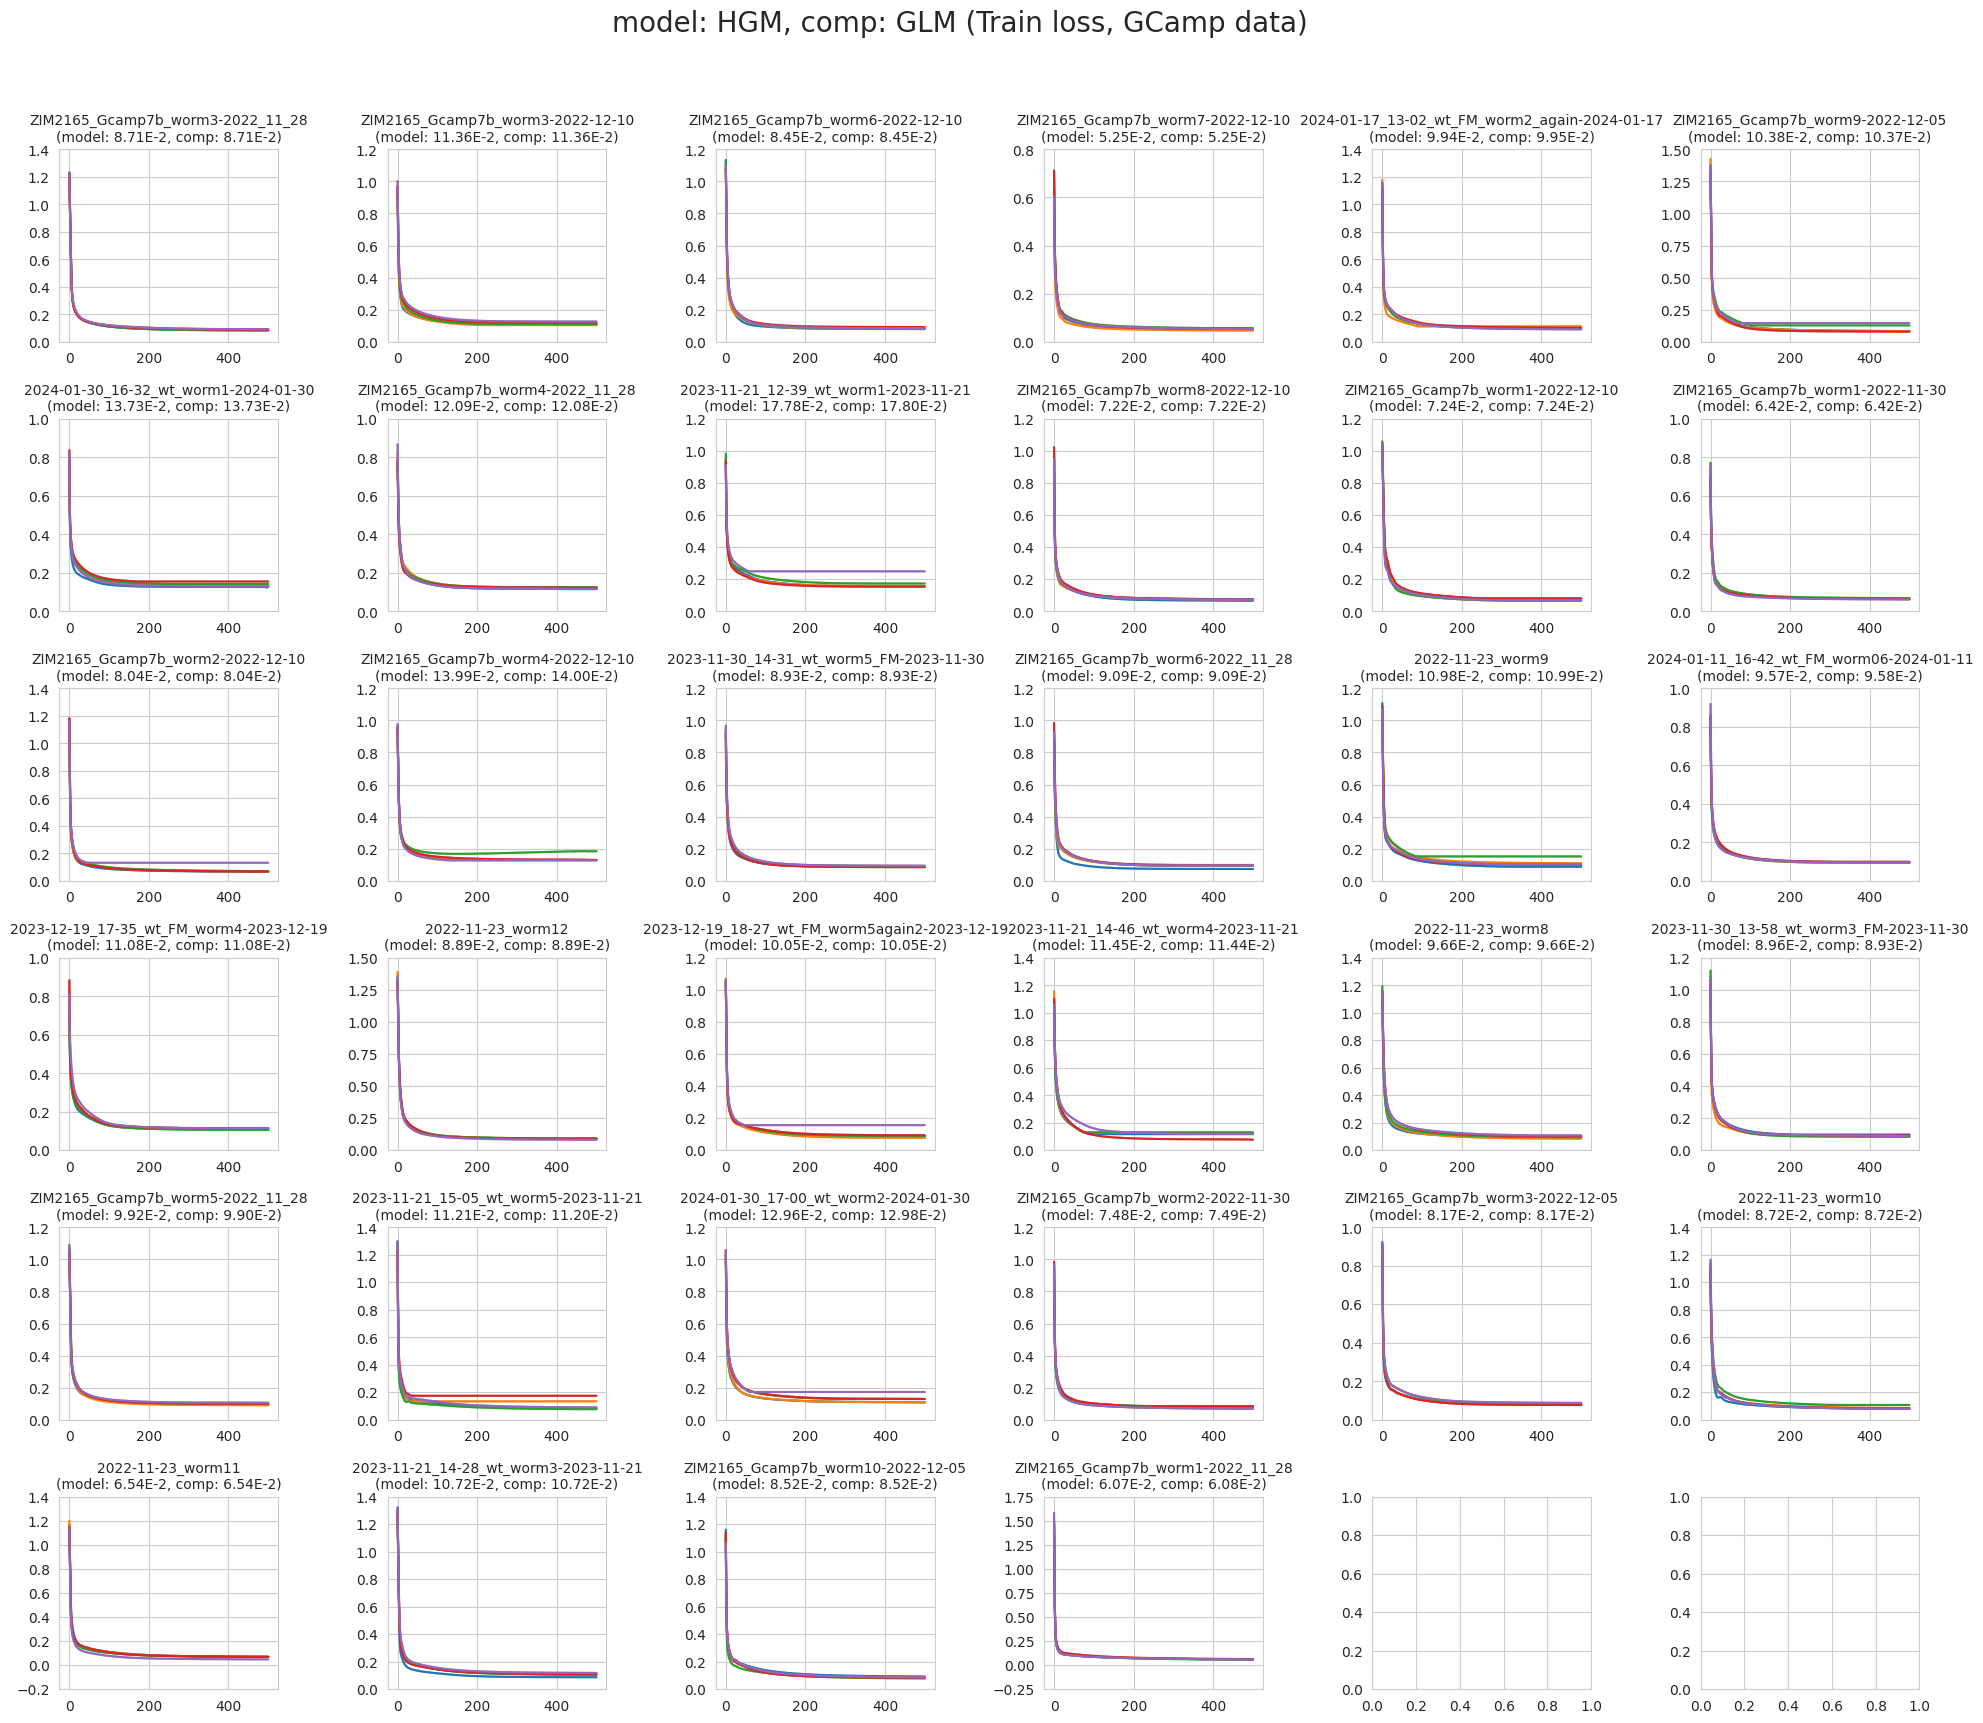

In [8]:
plot_utils.plot_losses(filenames, hgm_models_losses_tr, glm_models_losses_tr, 'model: HGM, comp: GLM (Train loss, GCamp data)')

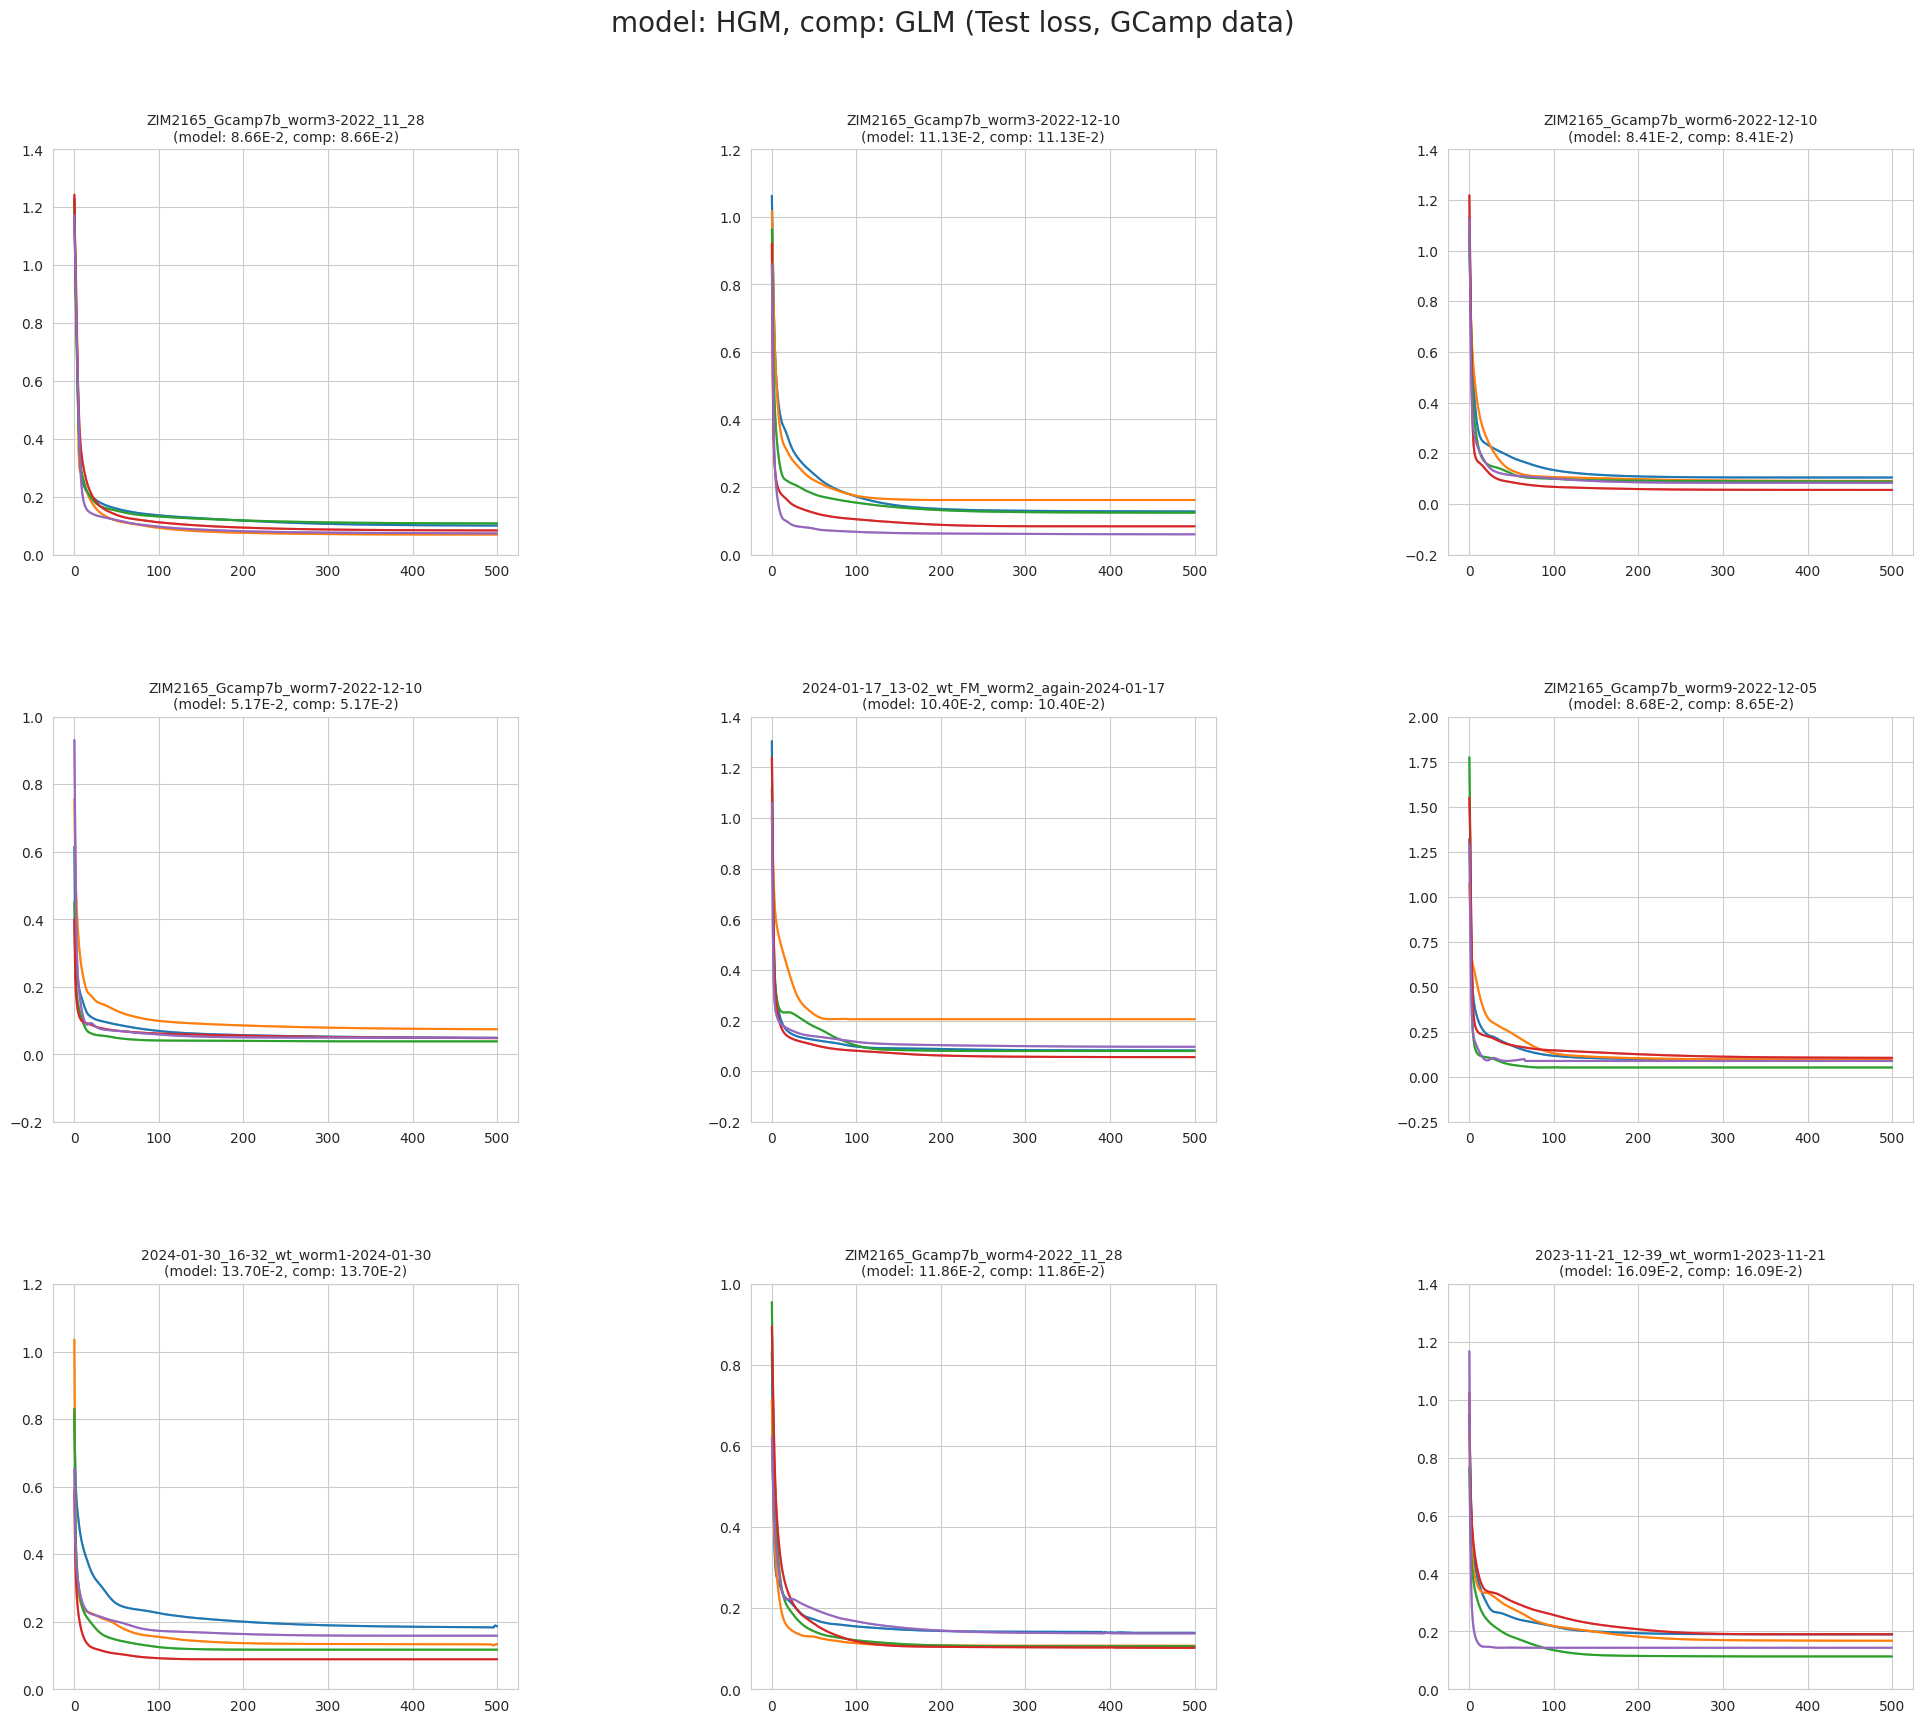

In [9]:
plot_utils.plot_losses(filenames, hgm_models_losses, glm_models_losses, 'model: HGM, comp: GLM (Test loss, GCamp data)', 9)

# GFP DATA

In [10]:
path_gfp = f'{os.getcwd()}/../data/{os.path.basename(os.getcwd())}/exported_data_gfp/'
filenames_gfp, continuous_behaviors_gfp, discrete_states_gfp, eigenworms_gfp, kymographs_gfp, traces_gfp = read_utils.get_data(path_gfp)

### preprocessing

In [11]:
for i in range(len(filenames_gfp)):
	mask = eigenworms_gfp[i].notna().all(axis=1)
	#continuous_behaviors_gfp[i] = continuous_behaviors_gfp[i][mask]
	discrete_states_gfp[i] = discrete_states_gfp[i][mask]
	eigenworms_gfp[i] = eigenworms_gfp[i][mask]
	traces_gfp[i] = traces_gfp[i][mask]

	#kymographs_gfp[i] = kymographs_gfp[i][mask]
	#filenames_gfp[i] = filenames_gfp[i][mask]

### GLM

In [13]:
selection = ['REV', 'VENTRAL_TURN', 'DORSAL_TURN', 'PAUSE']

# hgm_models_params_gfp = list()
glm_models_scores_gfp = list()
glm_models_losses_gfp = list()
glm_models_losses_tr_gfp = list()
for i in range(len(filenames_gfp)):
	print(f'{i+1}/{len(filenames_gfp)}: {filenames_gfp[i]}  ', end='')

	cv = StratifiedKFold(n_splits=5)
	splits = list(cv.split(np.zeros(traces_gfp[i].shape[0]), discrete_states_gfp[i]['REV'].values))

	neuron_scores_per_split, losses_per_plit, losses_tr_per_split = train_joint_model(glm, splits,
																					  jnp.array(traces_gfp[i].values),
																					  jnp.array(eigenworms_gfp[i].values),
																					  jnp.array(discrete_states_gfp[i][selection].values))

	glm_models_scores_gfp.append(neuron_scores_per_split)

	glm_models_losses_gfp.append(losses_per_plit)
	glm_models_losses_tr_gfp.append(losses_tr_per_split)

1/8: ZIM2319_GFP_worm3-2022-12-10_no_image_data  2/8: ZIM2319_GFP_worm1-2022-12-10_no_image_data  3/8: ZIM2319_GFP_worm2-2022-12-10_no_image_data  4/8: ZIM2319_GFP_worm6-2022-12-10_no_image_data  5/8: ZIM2319_GFP_worm8-2022-12-10_no_image_data  6/8: ZIM2319_GFP_worm4-2022-12-10_no_image_data  7/8: ZIM2319_GFP_worm7-2022-12-10_no_image_data  8/8: ZIM2319_GFP_worm5-2022-12-10_no_image_data  

### HGM

In [12]:
selection = ['REV', 'VENTRAL_TURN', 'DORSAL_TURN', 'PAUSE']

# hgm_models_params_gfp = list()
hgm_models_scores_gfp = list()
hgm_models_losses_gfp = list()
hgm_models_losses_tr_gfp = list()
for i in range(len(filenames_gfp)):
	print(f'{i+1}/{len(filenames_gfp)}: {filenames_gfp[i]}  ', end='')

	cv = StratifiedKFold(n_splits=5)
	splits = list(cv.split(np.zeros(traces_gfp[i].shape[0]), discrete_states_gfp[i]['REV'].values))

	neuron_scores_per_split, losses_per_plit, losses_tr_per_split = train_joint_model(hgm, splits,
																					  jnp.array(traces_gfp[i].values),
																					  jnp.array(eigenworms_gfp[i].values),
																					  jnp.array(discrete_states_gfp[i][selection].values))

	hgm_models_scores_gfp.append(neuron_scores_per_split)

	hgm_models_losses_gfp.append(losses_per_plit)
	hgm_models_losses_tr_gfp.append(losses_tr_per_split)

1/8: ZIM2319_GFP_worm3-2022-12-10_no_image_data  2/8: ZIM2319_GFP_worm1-2022-12-10_no_image_data  3/8: ZIM2319_GFP_worm2-2022-12-10_no_image_data  4/8: ZIM2319_GFP_worm6-2022-12-10_no_image_data  5/8: ZIM2319_GFP_worm8-2022-12-10_no_image_data  6/8: ZIM2319_GFP_worm4-2022-12-10_no_image_data  7/8: ZIM2319_GFP_worm7-2022-12-10_no_image_data  8/8: ZIM2319_GFP_worm5-2022-12-10_no_image_data  

### plots

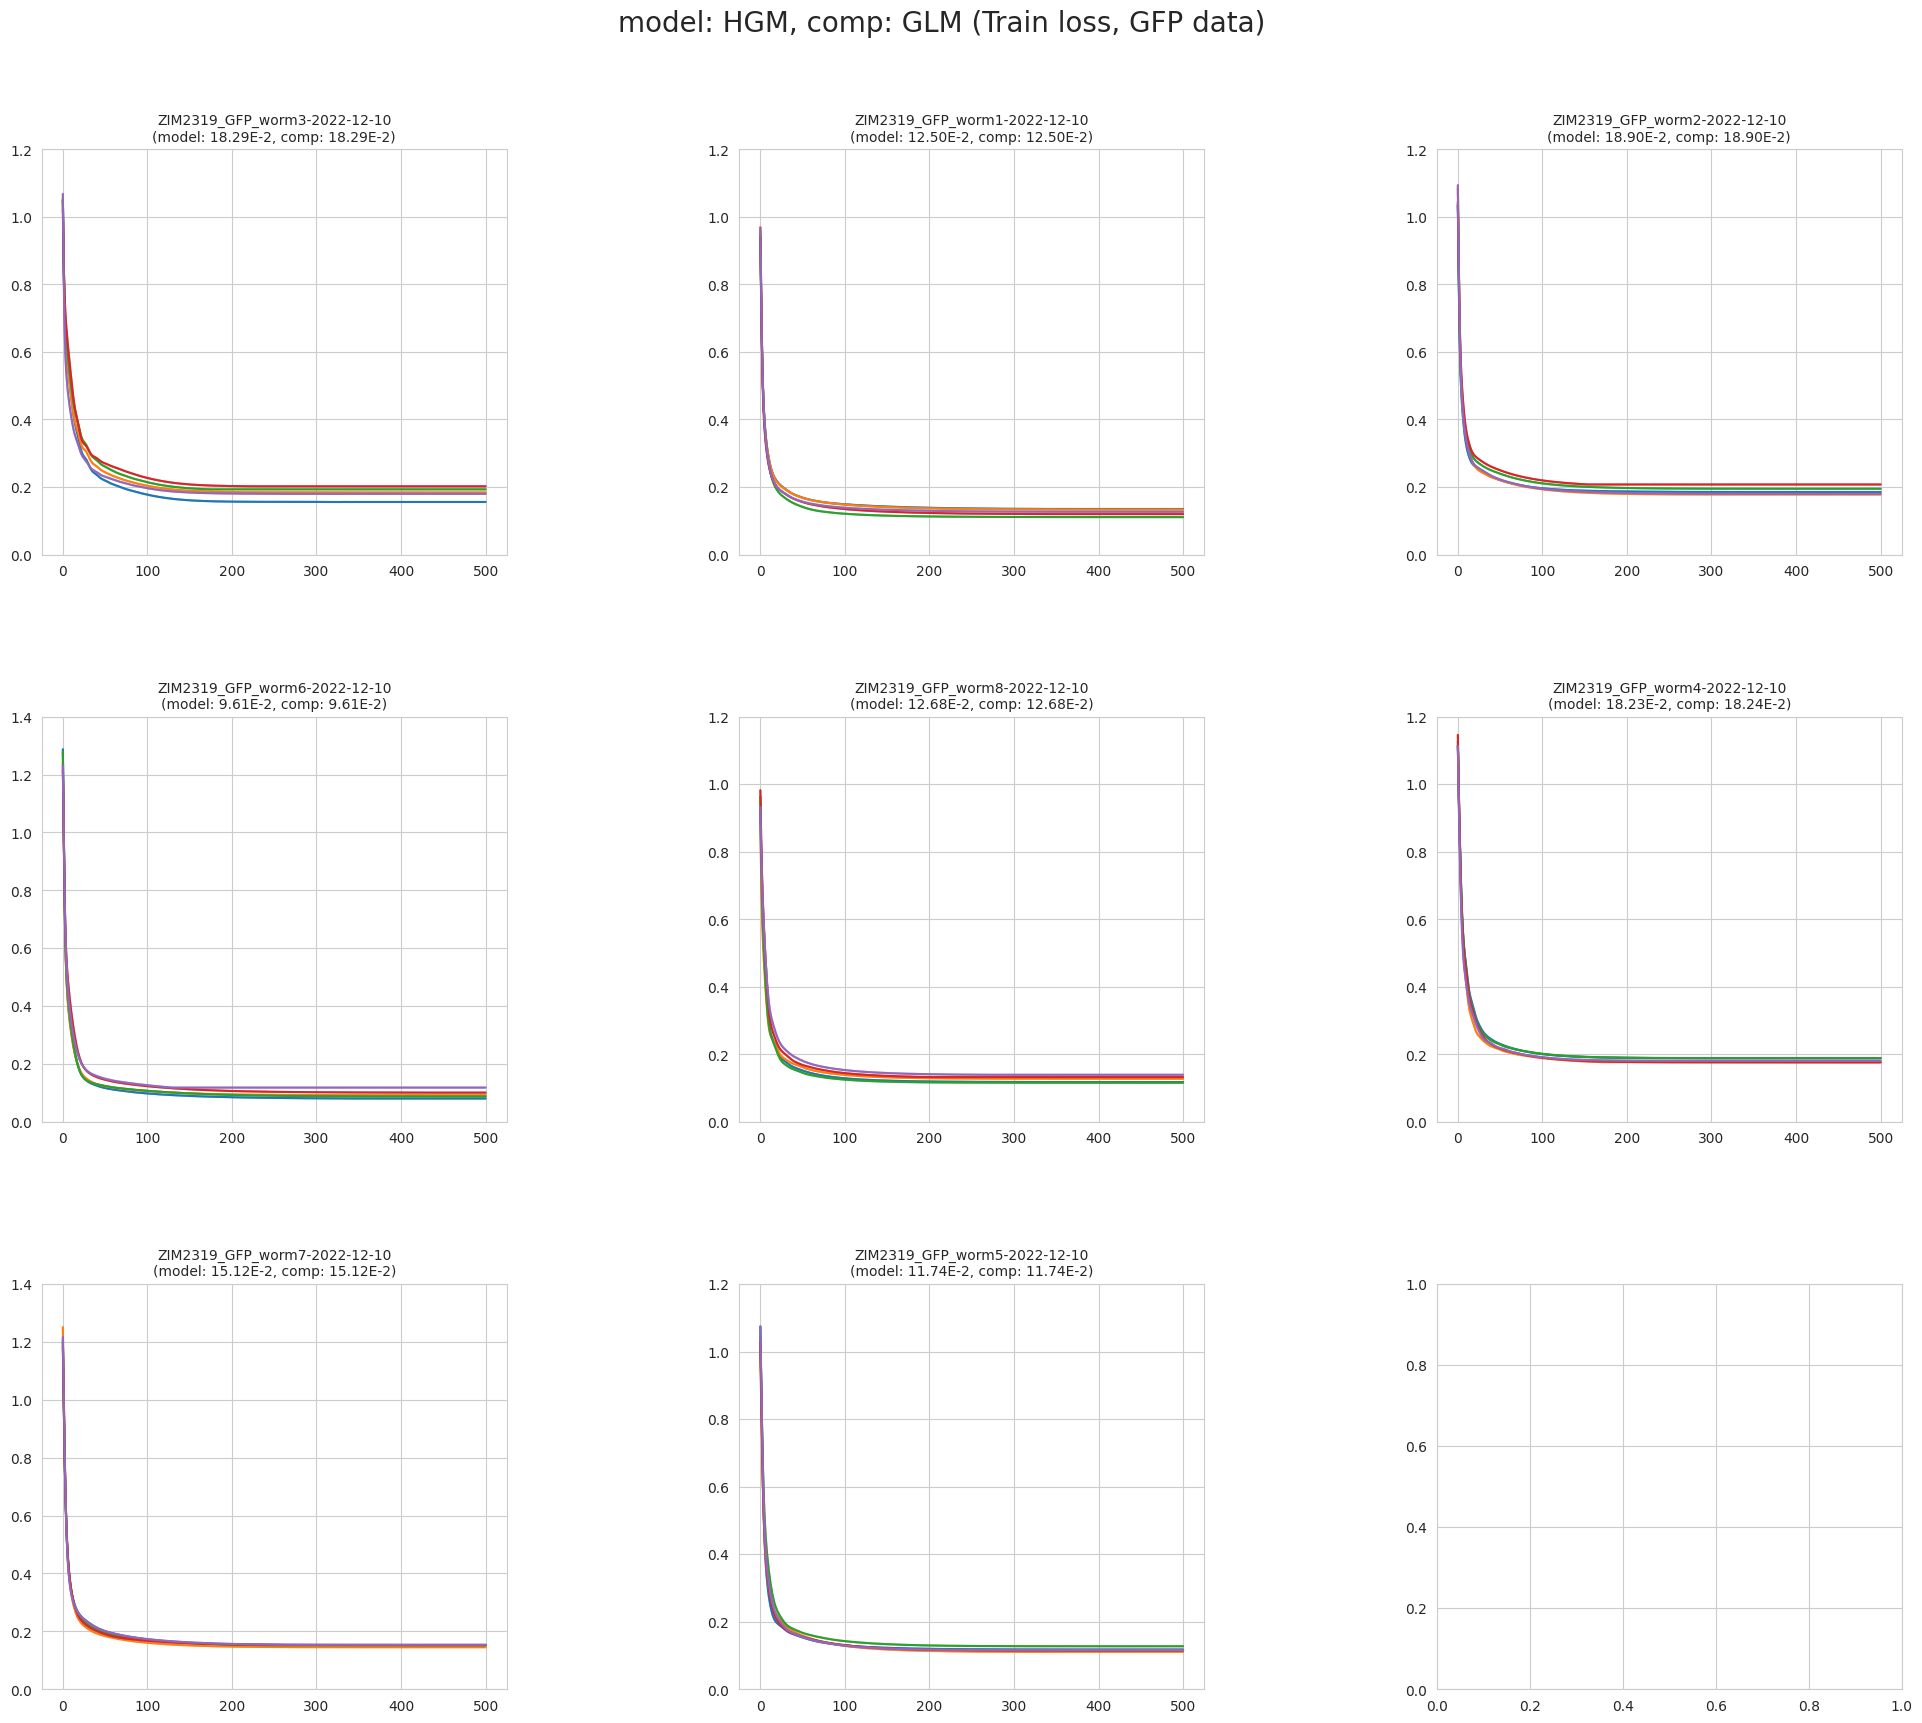

In [14]:
plot_utils.plot_losses(filenames_gfp, hgm_models_losses_tr_gfp, glm_models_losses_tr_gfp, 'model: HGM, comp: GLM (Train loss, GFP data)')

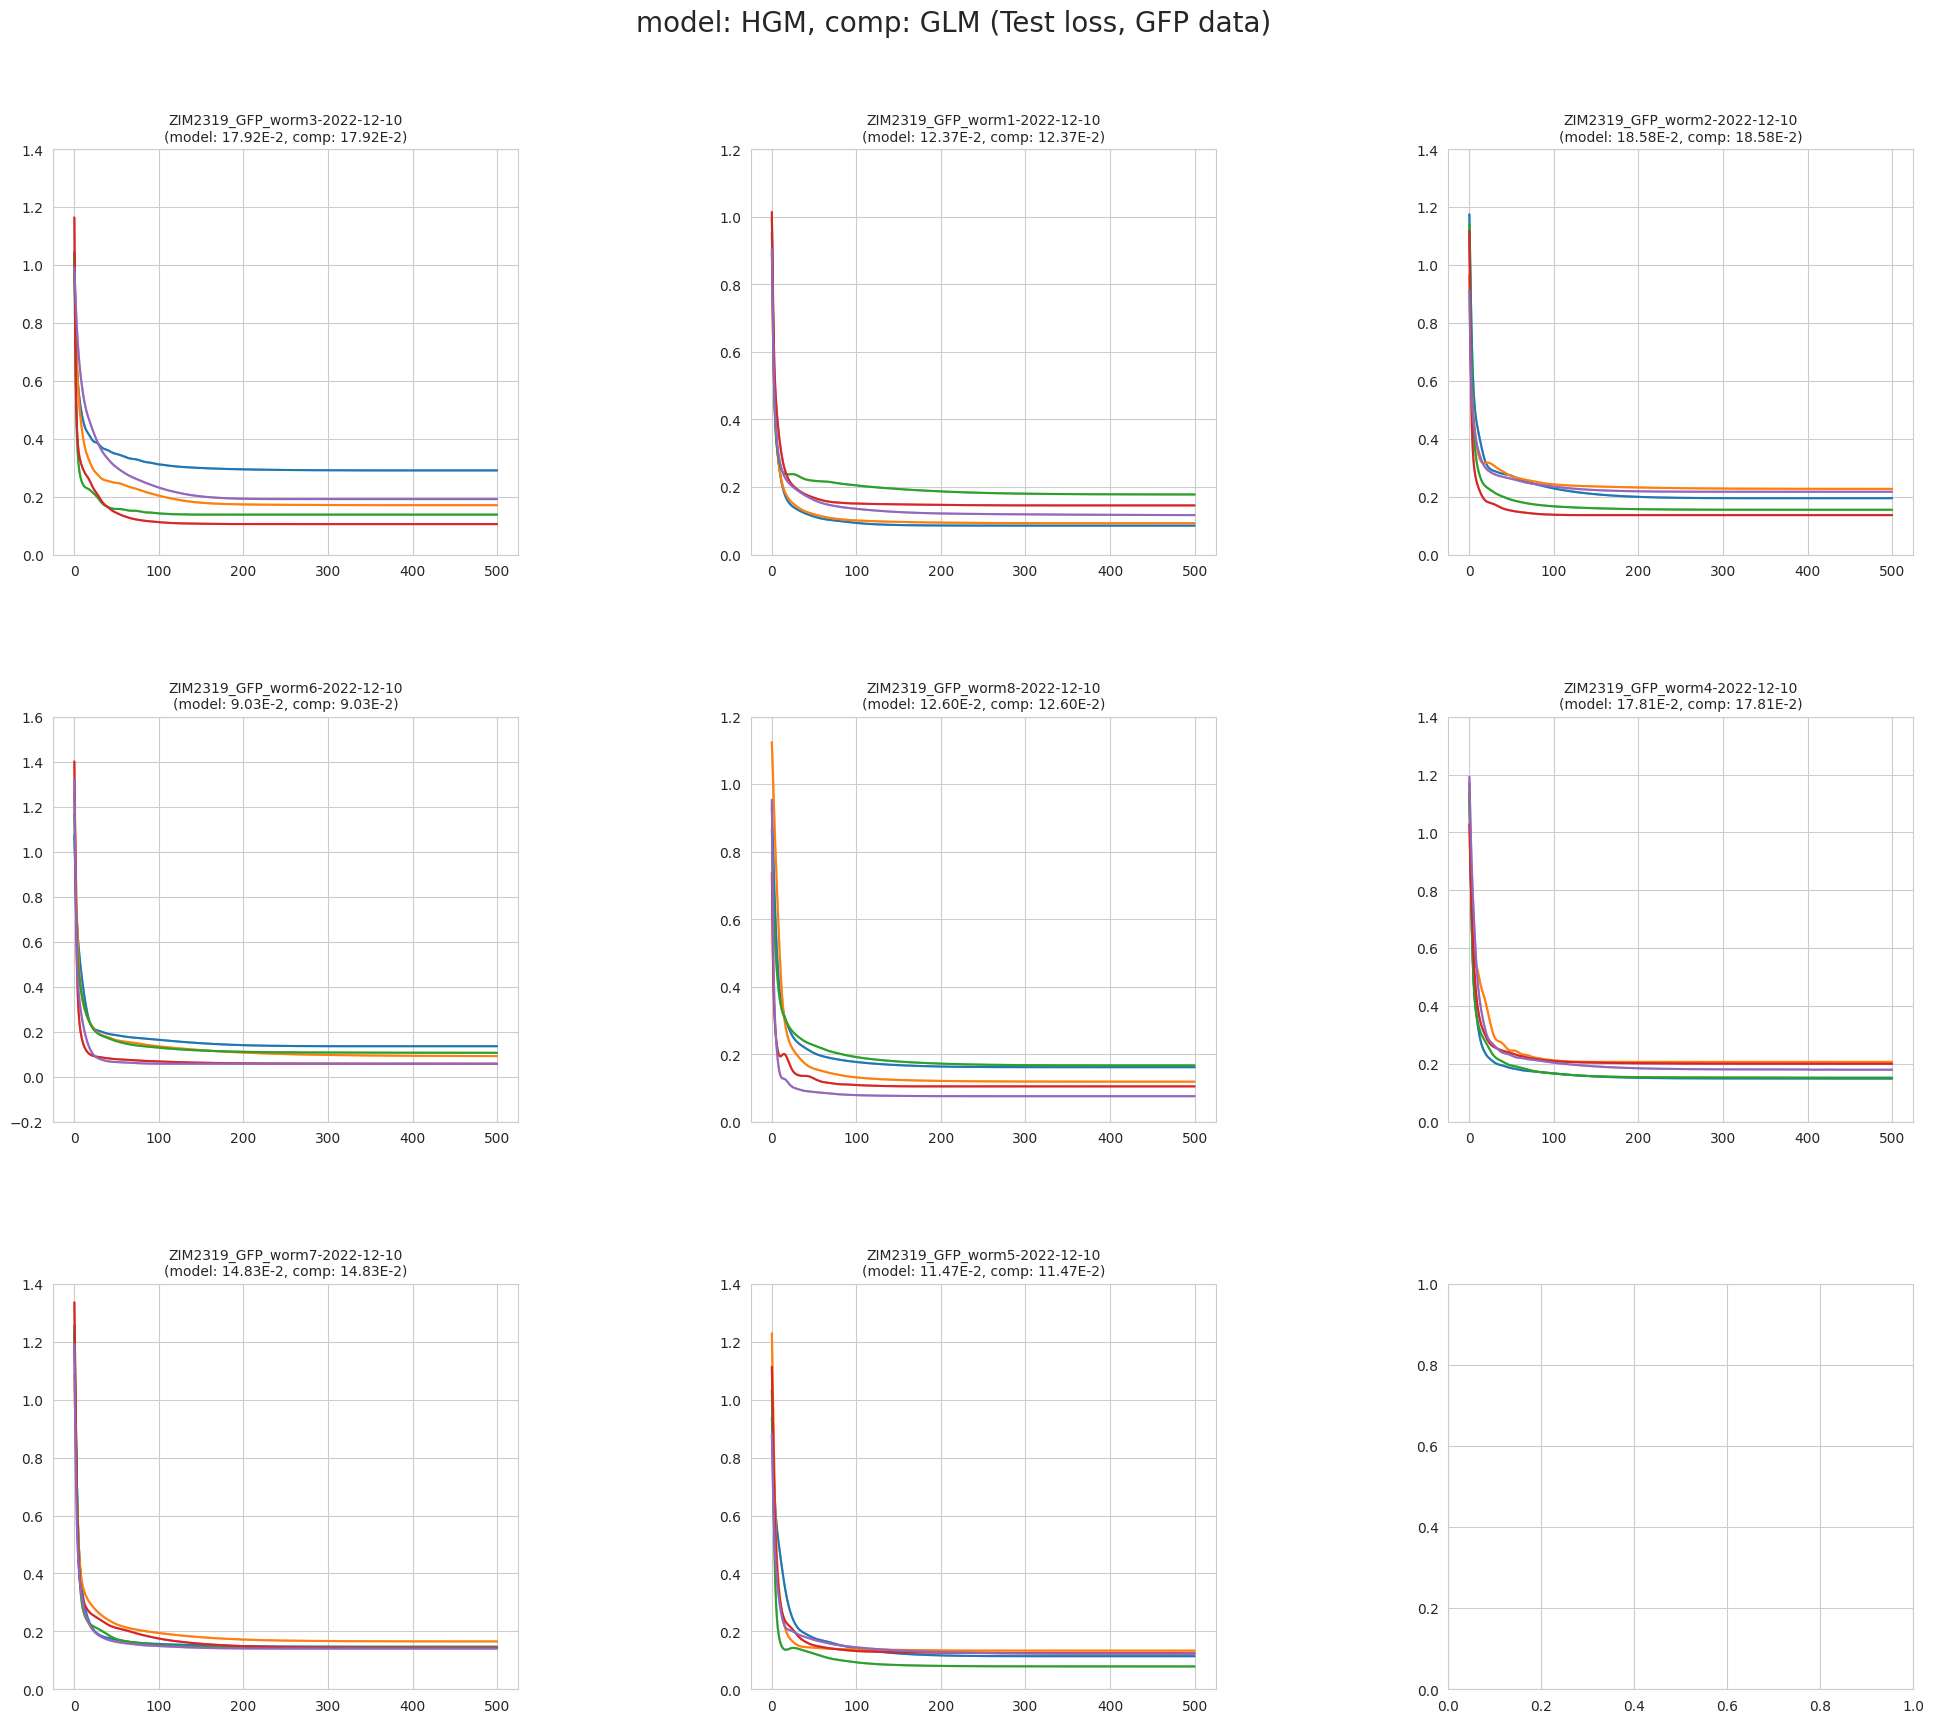

In [15]:
plot_utils.plot_losses(filenames_gfp, hgm_models_losses_gfp, glm_models_losses_gfp, 'model: HGM, comp: GLM (Test loss, GFP data)')

# assemble

In [16]:
neurons_labels = [traces[i].columns for i in range(len(filenames))]

unique_labels = sorted(list(set([l for label in neurons_labels for l in label])))
unique_labels_filtered = [label for label in unique_labels if label != '' and label[-1] != '_']

neuron_scores = dict()
glm_models_avg_scores = [np.mean(scores, axis=0) for scores in glm_models_scores]
hgm_models_avg_scores = [np.mean(scores, axis=0) for scores in hgm_models_scores]
for label_list, score_glm_list, score_hgm_list in zip(neurons_labels, glm_models_avg_scores, hgm_models_avg_scores):
	for i in range(len(label_list)):
		label = label_list[i]
		if label != '' and label[-1] != '_':
			score_glm_new, score_hgm_new = np.array(score_glm_list[i]), np.array(score_hgm_list[i])
			if len(score_hgm_new.shape) == 0:
				score_glm_new = score_glm_new.reshape(1, 1)
				score_hgm_new = score_hgm_new.reshape(1, 1)
			if label not in neuron_scores.keys():
				neuron_scores[label] = (score_glm_new, score_hgm_new)
			else:
				score_glm_prev, score_hgm_prev = neuron_scores[label]
				neuron_scores[label] = (np.vstack([score_glm_prev, score_glm_new]), np.vstack([score_hgm_prev, score_hgm_new]))

In [17]:
neurons_labels_gfp = [traces_gfp[i].columns for i in range(len(filenames_gfp))]

unique_labels_gfp = sorted(list(set([l for label in neurons_labels_gfp for l in label])))
unique_labels_filtered_gfp = [label for label in unique_labels_gfp if label != '' and label[-1] != '_']

neuron_scores_gfp = dict()
glm_models_avg_scores_gfp = [np.mean(scores, axis=0) for scores in glm_models_scores_gfp]
hgm_models_avg_scores_gfp = [np.mean(scores, axis=0) for scores in hgm_models_scores_gfp]
for label_list, score_glm_list, score_hgm_list in zip(neurons_labels_gfp, glm_models_avg_scores_gfp, hgm_models_avg_scores_gfp):
	for i in range(len(label_list)):
		label = label_list[i]
		if label != '' and label[-1] != '_':
			score_glm_new, score_hgm_new = np.array(score_glm_list[i]), np.array(score_hgm_list[i])
			if len(score_hgm_new.shape) == 0:
				score_glm_new = score_glm_new.reshape(1, 1)
				score_hgm_new = score_hgm_new.reshape(1, 1)
			if label not in neuron_scores_gfp.keys():
				neuron_scores_gfp[label] = (score_glm_new, score_hgm_new)
			else:
				score_glm_prev, score_hgm_prev = neuron_scores_gfp[label]
				neuron_scores_gfp[label] = (np.vstack([score_glm_prev, score_glm_new]), np.vstack([score_hgm_prev, score_hgm_new]))

# Plots

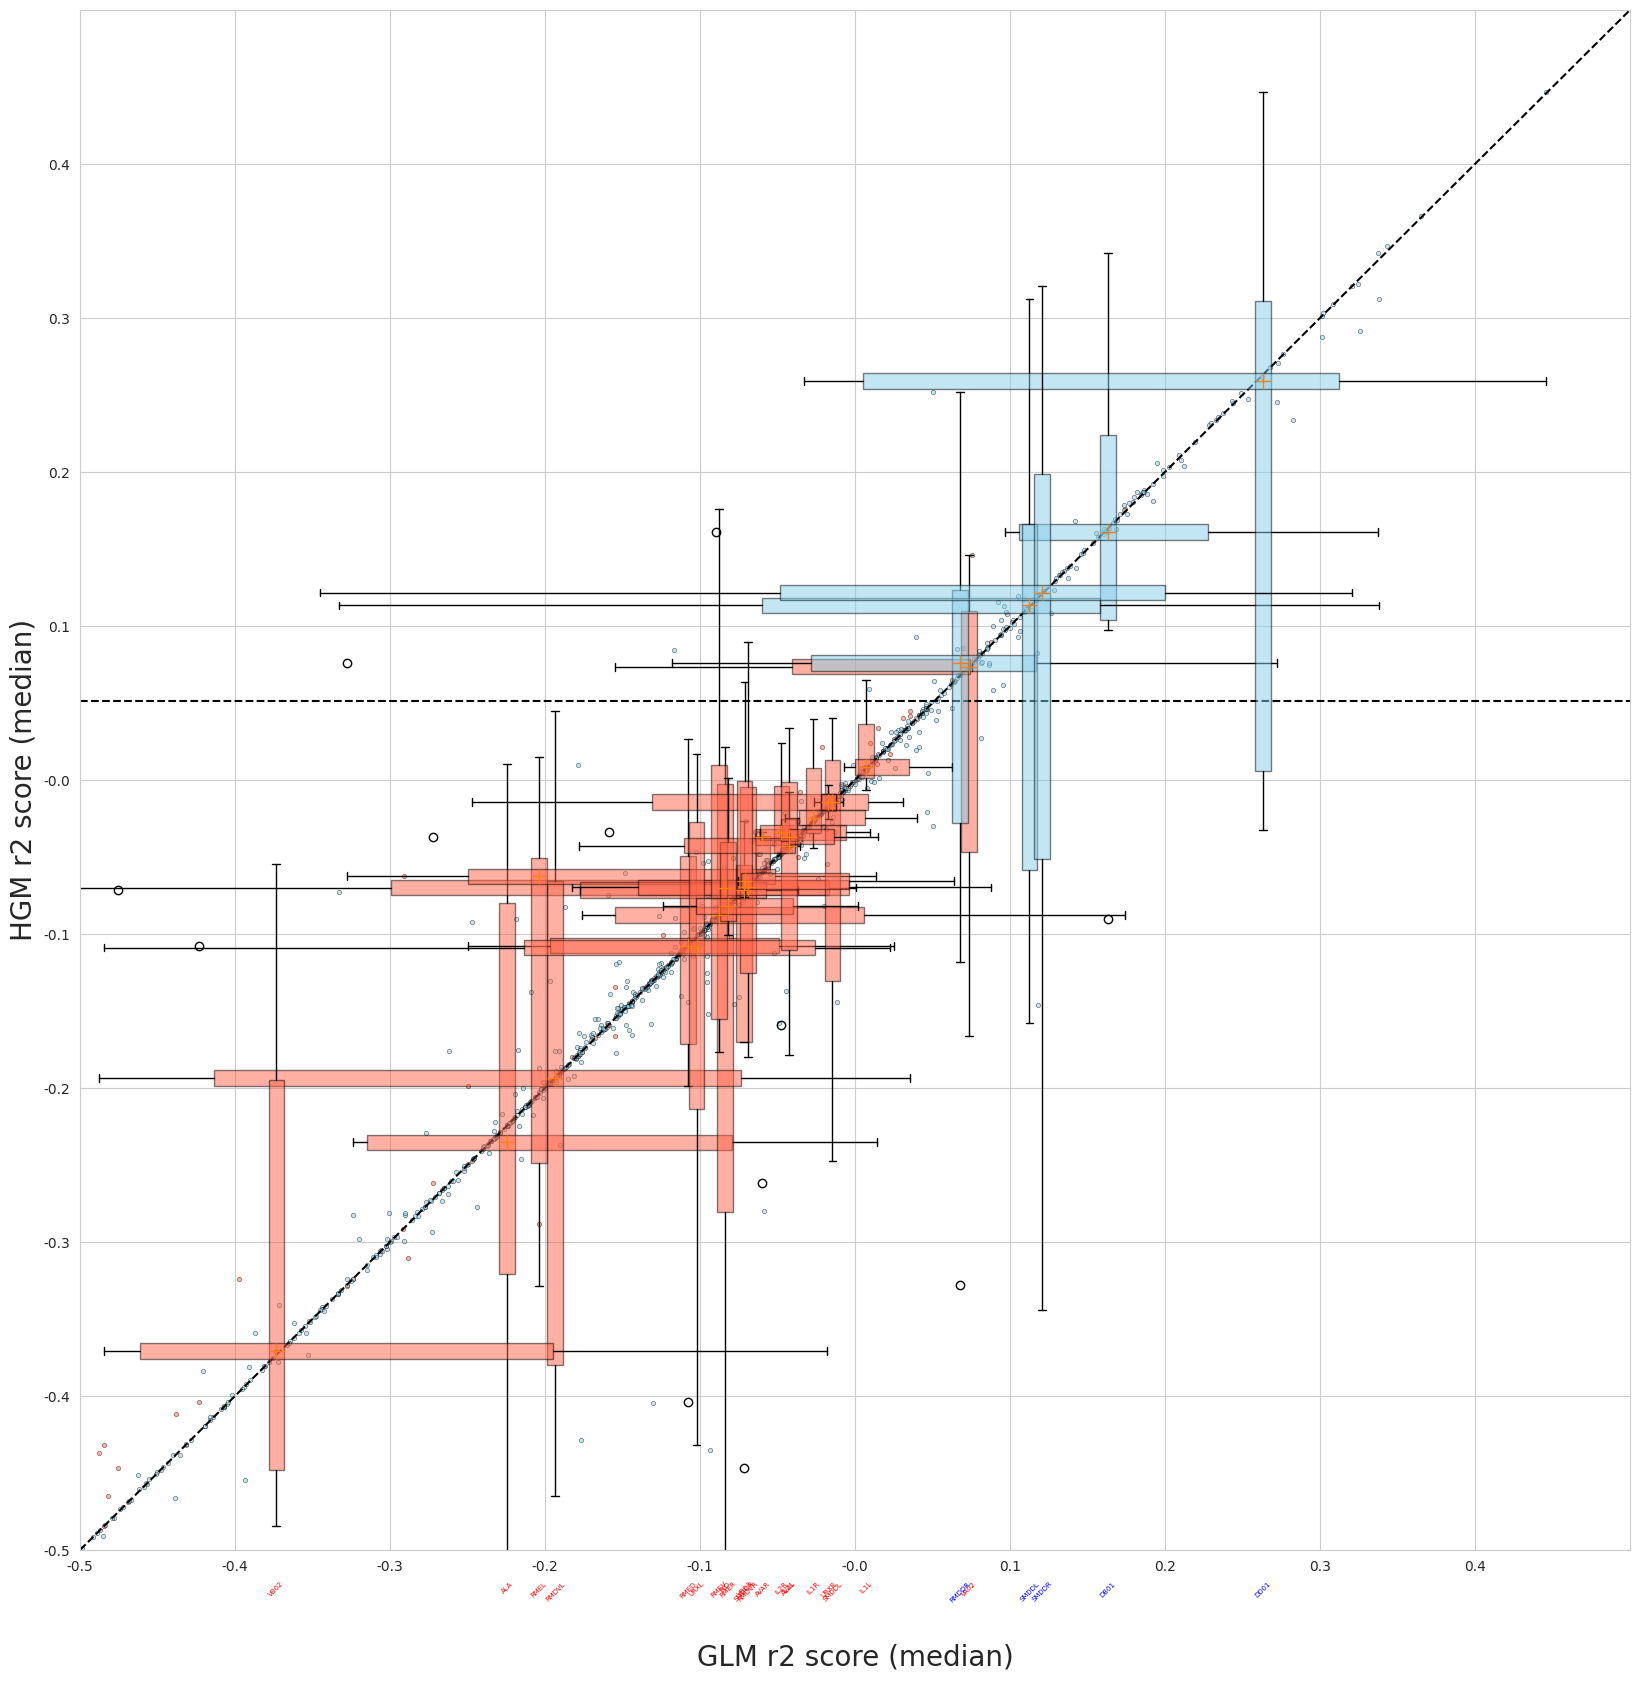

In [18]:
plot_utils.plot_performance_plot(neuron_scores, neuron_scores_gfp, save=False)

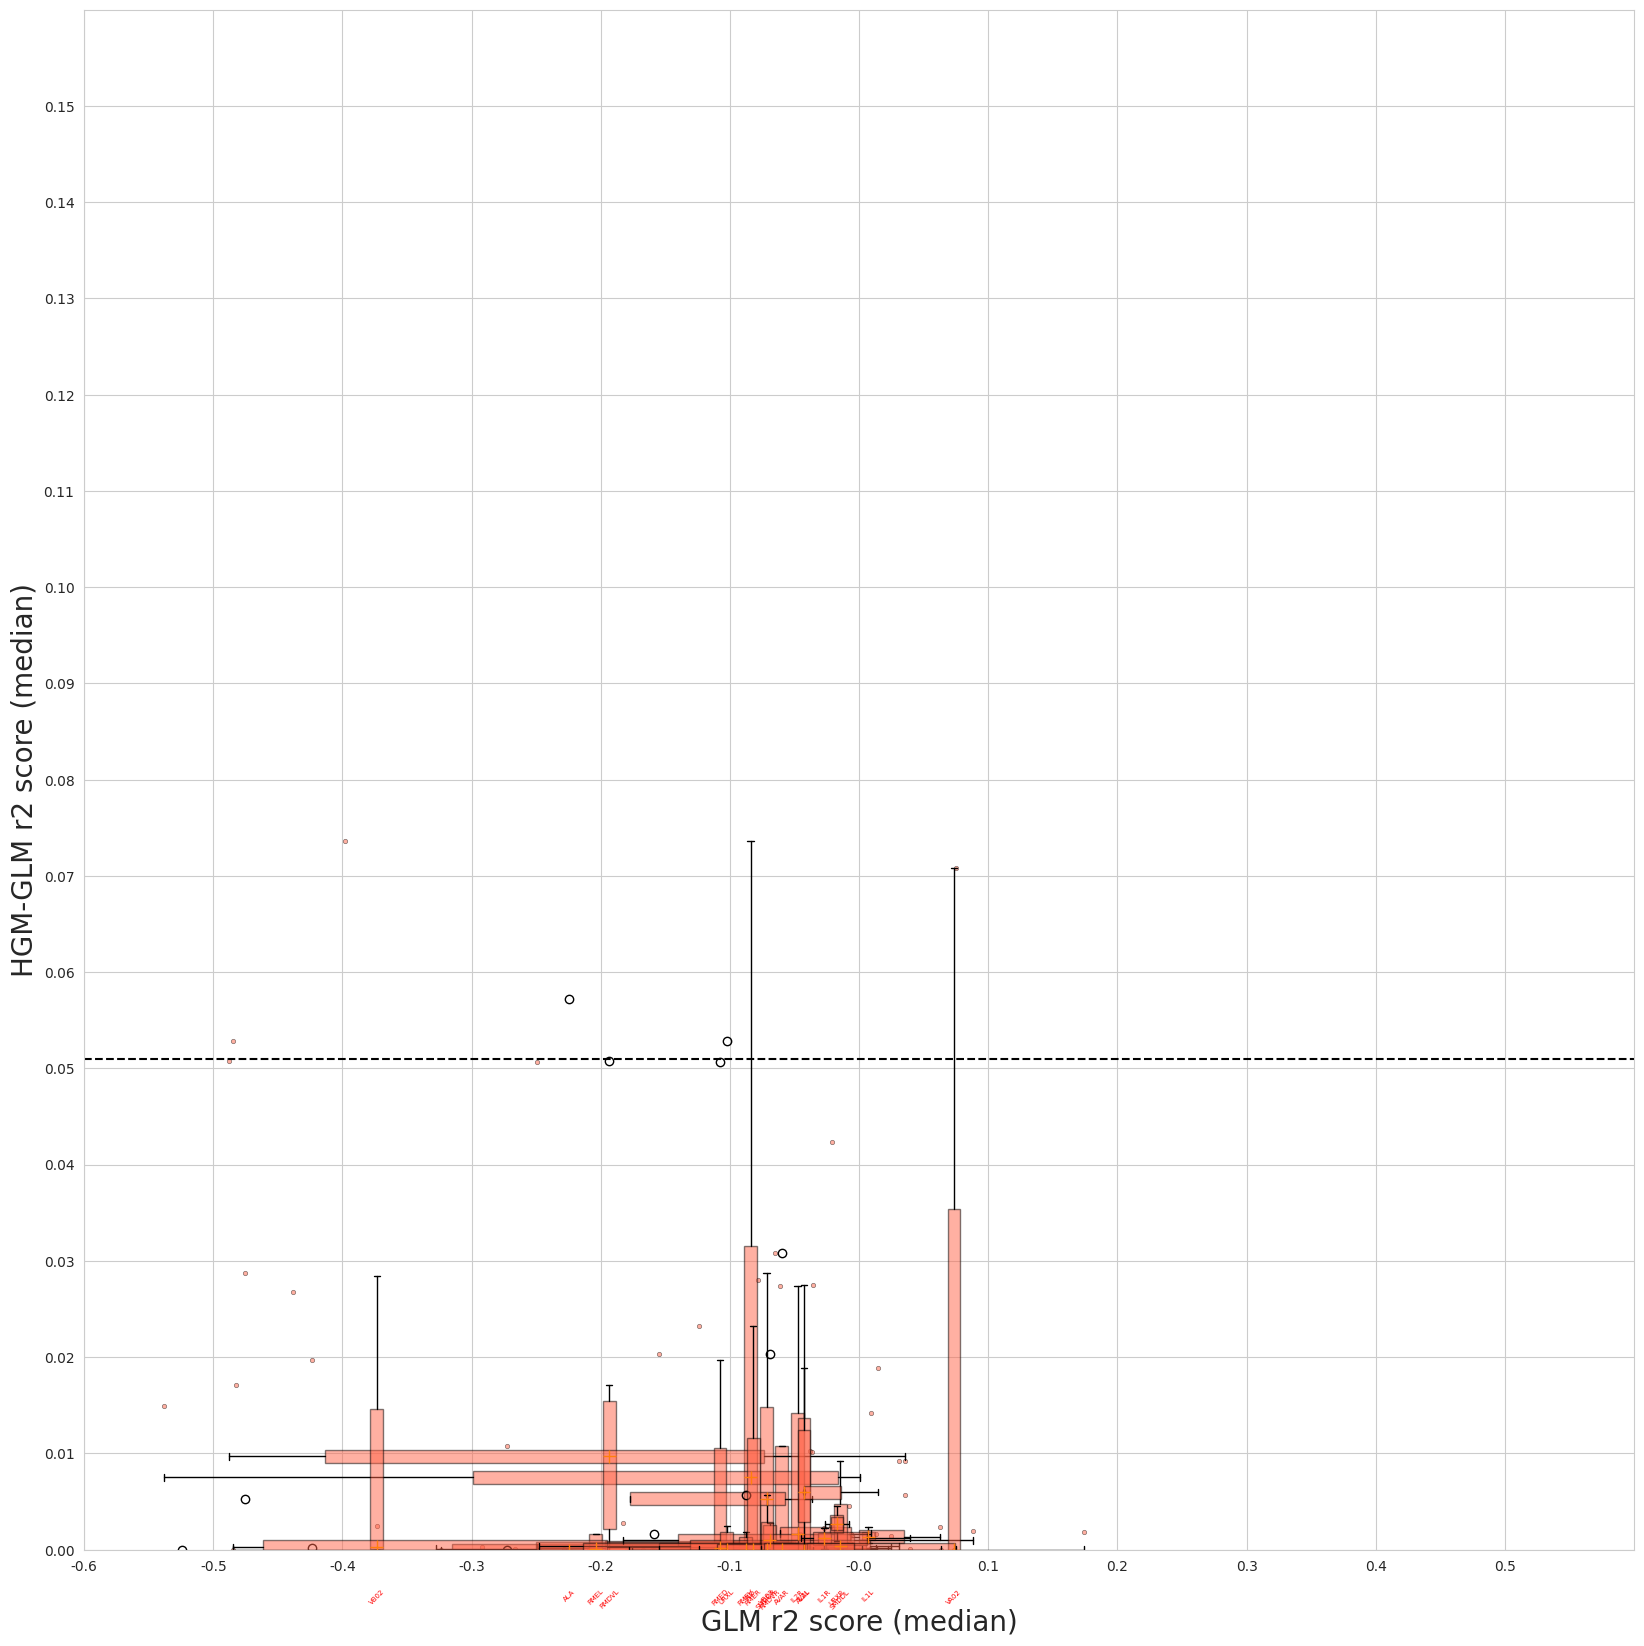

In [19]:
plot_utils.plot_improvement_plot(neuron_scores, neuron_scores_gfp, save=False)